# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Fahmi Alfayadh | 5054251015 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **PyTorch** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [2]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Dari torch, import juga torch.nn dan TensorDataset, DataLoader dari torch.utils.data.
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan torch.manual_seed(42) dan np.random.seed(42).
import polars as pl
import polars.selectors as cs
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch 
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

torch.manual_seed(42)
np.random.seed(42)

In [3]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.

data = pl.read_csv("Churn_Modelling.csv")

print(f"Jumlah baris: {data.shape[0]}, Jumlah kolom: {data.shape[1]}")
print(f"Tipe data:\n{data.dtypes}")
print(f"Statistik deskriptif:\n{data.describe()}")
print(f"Jumlah missing value:\n{data.null_count().to_dicts()}")
print(f"Jumlah baris duplikat: {data.is_duplicated().sum()}")

Jumlah baris: 10000, Jumlah kolom: 14
Tipe data:
[Int64, Int64, String, Int64, String, String, Int64, Int64, Float64, Int64, Int64, Int64, Float64, Int64]
Statistik deskriptif:
shape: (9, 15)
┌────────────┬────────────┬───────────┬─────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ statistic  ┆ RowNumber  ┆ CustomerI ┆ Surname ┆ … ┆ HasCrCard ┆ IsActiveM ┆ Estimated ┆ Exited   │
│ ---        ┆ ---        ┆ d         ┆ ---     ┆   ┆ ---       ┆ ember     ┆ Salary    ┆ ---      │
│ str        ┆ f64        ┆ ---       ┆ str     ┆   ┆ f64       ┆ ---       ┆ ---       ┆ f64      │
│            ┆            ┆ f64       ┆         ┆   ┆           ┆ f64       ┆ f64       ┆          │
╞════════════╪════════════╪═══════════╪═════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ count      ┆ 10000.0    ┆ 10000.0   ┆ 10000   ┆ … ┆ 10000.0   ┆ 10000.0   ┆ 10000.0   ┆ 10000.0  │
│ null_count ┆ 0.0        ┆ 0.0       ┆ 0       ┆ … ┆ 0.0       ┆ 0.0       ┆ 0.0       ┆ 0.0      │


In [4]:
data

RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
i64,i64,str,i64,str,str,i64,i64,f64,i64,i64,i64,f64,i64
1,15634602,"""Hargrave""",619,"""France""","""Female""",42,2,0.0,1,1,1,101348.88,1
2,15647311,"""Hill""",608,"""Spain""","""Female""",41,1,83807.86,1,0,1,112542.58,0
3,15619304,"""Onio""",502,"""France""","""Female""",42,8,159660.8,3,1,0,113931.57,1
4,15701354,"""Boni""",699,"""France""","""Female""",39,1,0.0,2,0,0,93826.63,0
5,15737888,"""Mitchell""",850,"""Spain""","""Female""",43,2,125510.82,1,1,1,79084.1,0
…,…,…,…,…,…,…,…,…,…,…,…,…,…
9996,15606229,"""Obijiaku""",771,"""France""","""Male""",39,5,0.0,2,1,0,96270.64,0
9997,15569892,"""Johnstone""",516,"""France""","""Male""",35,10,57369.61,1,1,1,101699.77,0
9998,15584532,"""Liu""",709,"""France""","""Female""",36,7,0.0,1,0,1,42085.58,1


In [5]:
X = data.drop(["Exited", "RowNumber", "CustomerId", "Surname"])
y = data["Exited"]


num_cols = X.select(cs.numeric()).columns
cat_cols = X.select(~cs.numeric()).columns

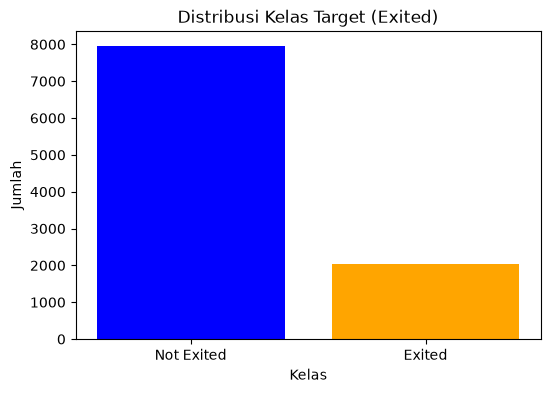

In [6]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.

_y = y.to_numpy().flatten()
plt.figure(figsize=(6, 4))
plt.bar(["Not Exited", "Exited"], [np.sum(_y == 0), np.sum(_y == 1)], color=["blue", "orange"])
plt.title("Distribusi Kelas Target (Exited)")
plt.xlabel("Kelas")
plt.ylabel("Jumlah")
plt.show()

data imbalanced 

In [7]:
num_cols

['CreditScore',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary']

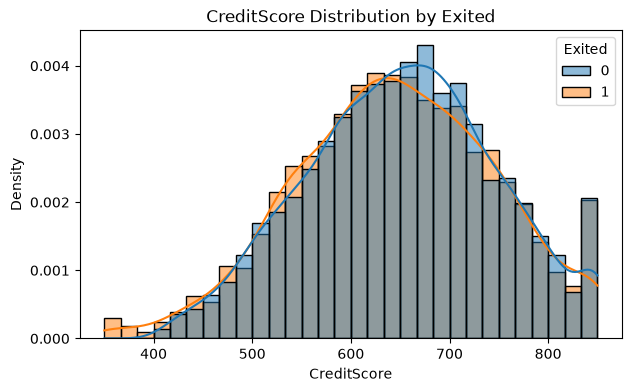

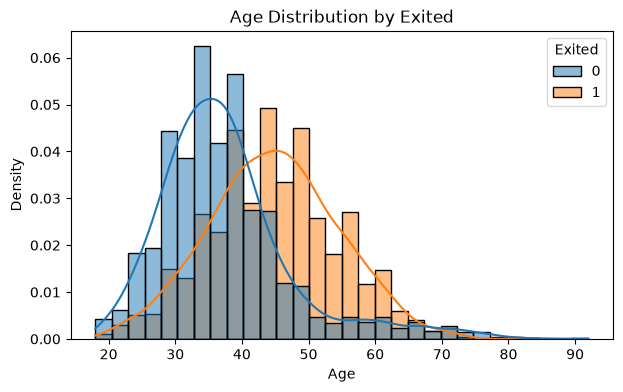

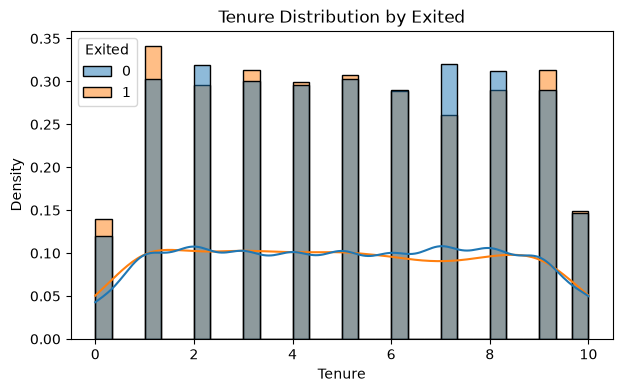

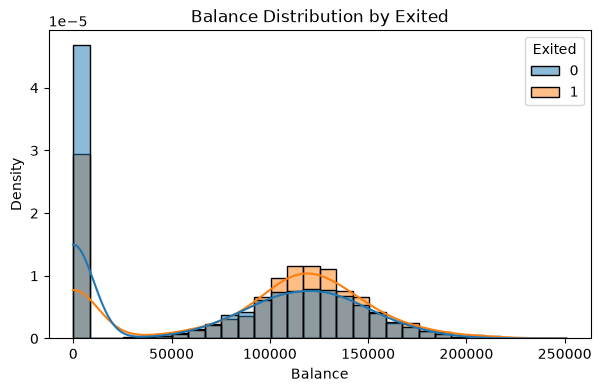

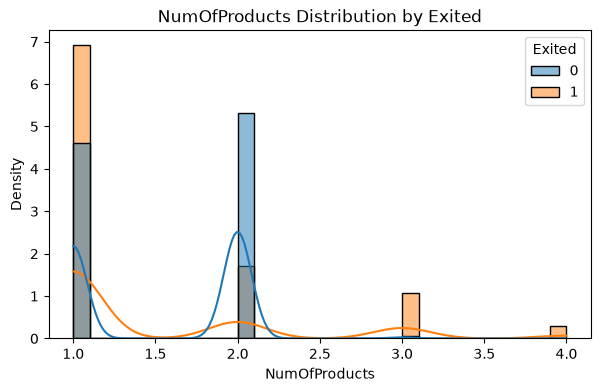

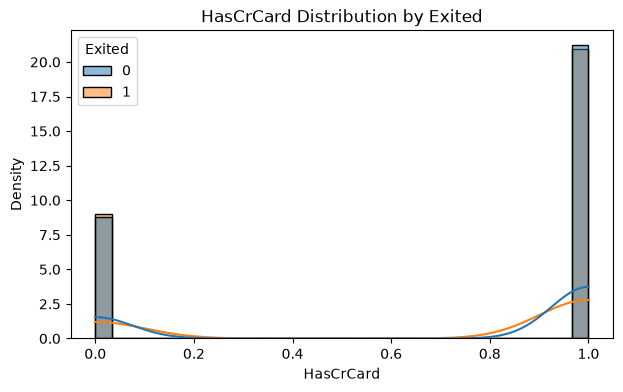

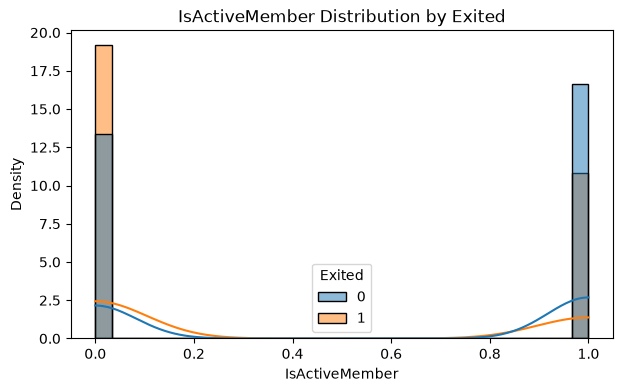

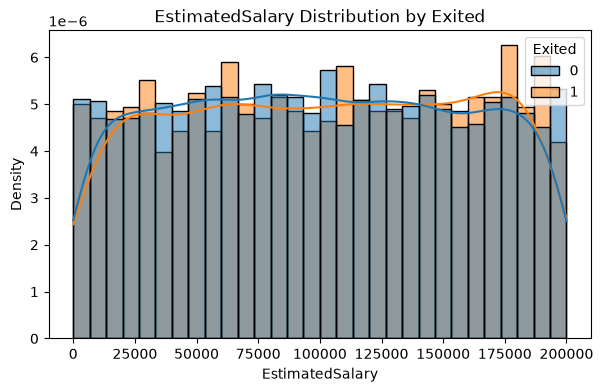

In [8]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.

df_pd = data.to_pandas().drop(columns=["RowNumber", "CustomerId", "Surname"])

for col in num_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df_pd, x=col, hue='Exited', kde=True,
                 bins=30, stat='density', common_norm=False)
    plt.title(f'{col} Distribution by Exited')
    plt.show()

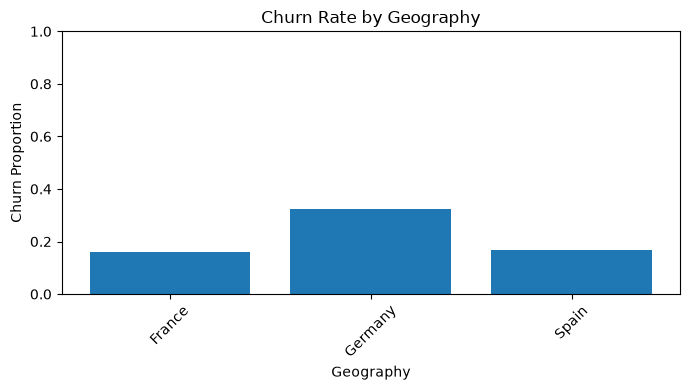

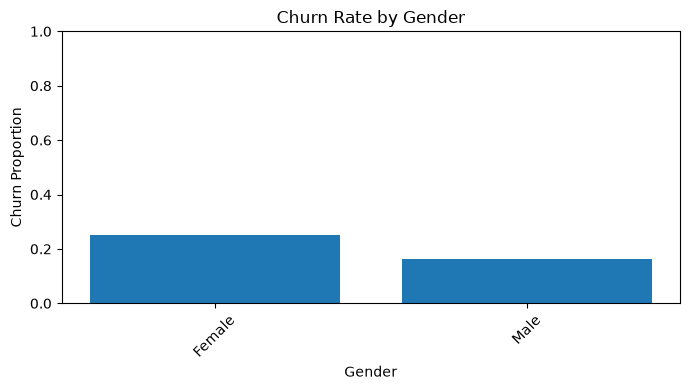

In [9]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).

for col in cat_cols:
    rates = (
        data.group_by(col)
        .agg(pl.col('Exited').mean().alias('Churn Rate'))
        .sort(col)
        .to_pandas()
    )

    plt.figure(figsize=(7, 4))
    plt.bar(rates[col].astype(str), rates['Churn Rate'])
    plt.title(f'Churn Rate by {col}')
    plt.xlabel(col)
    plt.ylabel('Churn Proportion')
    plt.ylim(0, 1)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [10]:
X

CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
i64,str,str,i64,i64,f64,i64,i64,i64,f64
619,"""France""","""Female""",42,2,0.0,1,1,1,101348.88
608,"""Spain""","""Female""",41,1,83807.86,1,0,1,112542.58
502,"""France""","""Female""",42,8,159660.8,3,1,0,113931.57
699,"""France""","""Female""",39,1,0.0,2,0,0,93826.63
850,"""Spain""","""Female""",43,2,125510.82,1,1,1,79084.1
…,…,…,…,…,…,…,…,…,…
771,"""France""","""Male""",39,5,0.0,2,1,0,96270.64
516,"""France""","""Male""",35,10,57369.61,1,1,1,101699.77
709,"""France""","""Female""",36,7,0.0,1,0,1,42085.58


In [11]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.

X = X.with_columns([
    pl.col("Gender").replace({"Female": 0, "Male": 1}).alias("Gender"),
])

cat_ngender = X.select(~cs.numeric()).columns
cat_ngender.remove("Gender")

In [12]:
cat_cols

['Geography', 'Gender']

In [13]:
transformer = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="first"), cat_ngender),
    ]
)

In [14]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.

# 70% train, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

In [15]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.

X_train_transformed = transformer.fit_transform(X_train)
X_val_transformed = transformer.fit_transform(X_val)
X_test_transformed = transformer.fit_transform(X_test)



In [16]:
# Ubah X dan y untuk train, validation, dan test menjadi tensor bertipe float32.
# Bentuk y diubah menjadi (N, 1) agar sesuai dengan output model, contoh: torch.tensor(y, dtype=torch.float32).view(-1, 1)
# Buat DataLoader untuk train set (shuffle=True) menggunakan TensorDataset.

X_train_tensor = torch.tensor(X_train_transformed, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.float32).view(-1, 1)

X_val_tensor = torch.tensor(X_val_transformed, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.to_numpy(), dtype=torch.float32).view(-1, 1)

X_test_tensor = torch.tensor(X_test_transformed, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.to_numpy(), dtype=torch.float32).view(-1, 1)

val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [17]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

logreg_model = LogisticRegression(random_state=42, max_iter=1000)
logreg_model.fit(X_train_transformed, y_train)

y_pred = logreg_model.predict(X_test_transformed)

# metricv
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
print(f"Logistic Regression Metrics:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")     



Logistic Regression Metrics:
Accuracy: 0.8113
Precision: 0.6196
Recall: 0.1869


## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer** dan **1 neuron output**. Di PyTorch, output layer cukup berupa `nn.Linear` tanpa Sigmoid, lalu gunakan **`nn.BCEWithLogitsLoss`** sebagai loss function. Loss ini sudah menggabungkan Sigmoid dan Binary Cross-Entropy sehingga lebih stabil secara numerik.

Contoh arsitektur: `Input → Linear(16) → ReLU → Linear(1)`

In [18]:
# Definisikan arsitektur ANN sederhana sebagai class turunan nn.Module (gunakan nn.Sequential, nn.Linear, dan nn.ReLU).
# Tampilkan arsitektur model dengan print(model) dan hitung jumlah parameternya: sum(p.numel() for p in model.parameters()).

class SimpleANN(nn.Module):
    def __init__(self, input_dim):
        super(SimpleANN, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
        )

    def forward(self, x):
        return self.model(x)



for param in SimpleANN(X_train_tensor.shape[1]).parameters():
    print(param.shape)

torch.Size([16, 10])
torch.Size([16])
torch.Size([1, 16])
torch.Size([1])


#### Training Function

In [19]:
# Tentukan loss function (nn.BCEWithLogitsLoss), optimizer (misalnya torch.optim.Adam), learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Untuk setiap batch: forward -> hitung loss -> optimizer.zero_grad() -> loss.backward() -> optimizer.step().
# Di akhir setiap epoch, hitung loss dan accuracy pada train set dan validation set (gunakan model.eval() dan torch.no_grad()),
# lalu simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.3 dan 3.4.

def train_model(model, train_loader, val_loader, loss_fn, optimizer, num_epochs, log_interval=1):
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        correct_train = 0
        total_train = 0

        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = loss_fn(outputs, y_batch)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * X_batch.size(0)
            predicted = (torch.sigmoid(outputs) > 0.5).float()
            correct_train += (predicted == y_batch).sum().item()
            total_train += y_batch.size(0)

        train_loss /= total_train
        train_acc = correct_train / total_train

        model.eval()
        val_loss = 0.0
        correct_val = 0
        total_val = 0

        with torch.no_grad():
            for X_val_batch, y_val_batch in val_loader:
                val_outputs = model(X_val_batch)
                v_loss = loss_fn(val_outputs, y_val_batch)

                val_loss += v_loss.item() * X_val_batch.size(0)
                predicted_val = (torch.sigmoid(val_outputs) > 0.5).float()
                correct_val += (predicted_val == y_val_batch).sum().item()
                total_val += y_val_batch.size(0)

        val_loss /= total_val
        val_acc = correct_val / total_val

        
        if (epoch + 1) % log_interval == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}], Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

    return history


In [20]:
epochs = 100
batch_size = 32

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

model = SimpleANN(X_train_tensor.shape[1])

loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    num_epochs=epochs,
    log_interval=10
)

print(f"Train Accuracy: {history['train_acc'][-1]:.4f}")
print(f"Validation Accuracy: {history['val_acc'][-1]:.4f}")
print(f"Train Loss: {history['train_loss'][-1]:.4f}")
print(f"Validation Loss: {history['val_loss'][-1]:.4f}")


Epoch [10/100], Train Loss: 0.3591, Train Acc: 0.8544, Val Loss: 0.3504, Val Acc: 0.8540
Epoch [20/100], Train Loss: 0.3495, Train Acc: 0.8557, Val Loss: 0.3400, Val Acc: 0.8567
Epoch [30/100], Train Loss: 0.3446, Train Acc: 0.8591, Val Loss: 0.3378, Val Acc: 0.8580
Epoch [40/100], Train Loss: 0.3427, Train Acc: 0.8589, Val Loss: 0.3346, Val Acc: 0.8567
Epoch [50/100], Train Loss: 0.3409, Train Acc: 0.8576, Val Loss: 0.3343, Val Acc: 0.8567
Epoch [60/100], Train Loss: 0.3398, Train Acc: 0.8596, Val Loss: 0.3340, Val Acc: 0.8580
Epoch [70/100], Train Loss: 0.3391, Train Acc: 0.8586, Val Loss: 0.3322, Val Acc: 0.8600
Epoch [80/100], Train Loss: 0.3385, Train Acc: 0.8583, Val Loss: 0.3313, Val Acc: 0.8587
Epoch [90/100], Train Loss: 0.3376, Train Acc: 0.8603, Val Loss: 0.3307, Val Acc: 0.8593
Epoch [100/100], Train Loss: 0.3367, Train Acc: 0.8616, Val Loss: 0.3309, Val Acc: 0.8613
Train Accuracy: 0.8616
Validation Accuracy: 0.8613
Train Loss: 0.3367
Validation Loss: 0.3309


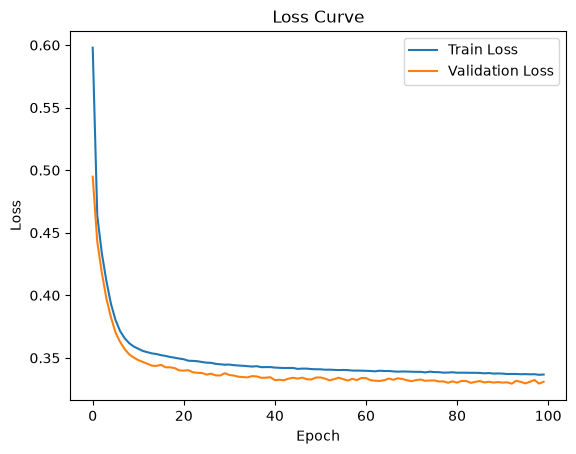

In [21]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot menggunakan dictionary history.

plt.Figure(figsize=(4, 10))
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()


In [22]:
# Lakukan prediksi pada test set. Gunakan model.eval() dan torch.no_grad().
# Output model berupa logit, ubah menjadi probabilitas dengan torch.sigmoid(), lalu menjadi label dengan threshold 0.5.
# Simpan probabilitas dan label dalam bentuk numpy array untuk keperluan evaluasi.
y_pred_probs = []
y_pred_labels = []

treshold = 0.5

with torch.no_grad():
    for X_test_batch, _ in test_loader:
        logits = model(X_test_batch)
        probs = torch.sigmoid(logits)
        labels = (probs > treshold).float()

        y_pred_probs.extend(probs.numpy().flatten())
        y_pred_labels.extend(labels.numpy().flatten())

print(f"Test Accuracy: {accuracy_score(y_test, y_pred_labels):.4f}")
print(f"Test Precision: {precision_score(y_test, y_pred_labels):.4f}")
print(f"Test Recall: {recall_score(y_test, y_pred_labels):.4f}")
print(f"Test F1-Score: {f1_score(y_test, y_pred_labels):.4f}")


Test Accuracy: 0.8593
Test Precision: 0.7350
Test Recall: 0.4820
Test F1-Score: 0.5822


## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

disini saya defenisikan 4 tipe model ANN:
1. **DeepANN**: ANN dengan 3 hidden layer dan Dropout (hanya 1 layer).
2. **DeepANN_withoutdo**: ANN dengan 3 hidden layer tanpa Dropout.
3. **DeepANN_bigdo**: ANN dengan 3 hidden layer dan Dropout di setiap layer.
4. **DeepANN_ultrabigdo**: ANN dengan 3 hidden layer, Dropout di setiap layer, dan nilai dropout lebih besar.

In [23]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan nn.Dropout(p) di antara hidden layer.
# Ingat: Dropout hanya aktif saat model.train() dan otomatis nonaktif saat model.eval().
# Tampilkan arsitektur model beserta jumlah parameternya.

class DeepANN(nn.Module):
    def __init__(self, input_dim):
        super(DeepANN, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Dropout(p=0.1),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 10),
            nn.ReLU(),
            nn.Linear(10, 6),
            nn.ReLU(),
            nn.Linear(6, 1),
        )

    def forward(self, x):
        return self.model(x)

class DeepANN_withoutdo(nn.Module):
    def __init__(self, input_dim):
        super(DeepANN_withoutdo, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 10),
            nn.ReLU(),
            nn.Linear(10, 6),
            nn.ReLU(),
            nn.Linear(6, 1),
        )

    def forward(self, x):
        return self.model(x)

class DeepANN_bigdo(nn.Module):
    def __init__(self, input_dim):
        super(DeepANN_bigdo, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            nn.Linear(16, 10),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            nn.Linear(10, 6),
            nn.ReLU(),
            nn.Linear(6, 1),
        )

    def forward(self, x):
        return self.model(x)

class DeepANN_ultrabigdo(nn.Module):
    def __init__(self, input_dim):
        super(DeepANN_ultrabigdo, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Dropout(p=0.4),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Dropout(p=0.4),
            nn.Linear(16, 10),
            nn.ReLU(),
            nn.Dropout(p=0.4),
            nn.Linear(10, 6),
            nn.ReLU(),
            nn.Linear(6, 1),
        )

    def forward(self, x):
        return self.model(x)
    
print("====================deepANN====================")
for param in DeepANN(X_train_tensor.shape[1]).parameters():
    print(param.shape)

print("====================deepANN_withoutdo====================")
for param in DeepANN_withoutdo(X_train_tensor.shape[1]).parameters():
    print(param.shape)

print("====================deepANN_bigdo====================")
for param in DeepANN_bigdo(X_train_tensor.shape[1]).parameters():
    print(param.shape)

print("====================deepANN_ultrabigdo====================")
for param in DeepANN_ultrabigdo(X_train_tensor.shape[1]).parameters():
    print(param.shape)


====================deepANN====================
torch.Size([32, 10])
torch.Size([32])
torch.Size([16, 32])
torch.Size([16])
torch.Size([10, 16])
torch.Size([10])
torch.Size([6, 10])
torch.Size([6])
torch.Size([1, 6])
torch.Size([1])
====================deepANN_withoutdo====================
torch.Size([32, 10])
torch.Size([32])
torch.Size([16, 32])
torch.Size([16])
torch.Size([10, 16])
torch.Size([10])
torch.Size([6, 10])
torch.Size([6])
torch.Size([1, 6])
torch.Size([1])
====================deepANN_bigdo====================
torch.Size([32, 10])
torch.Size([32])
torch.Size([16, 32])
torch.Size([16])
torch.Size([10, 16])
torch.Size([10])
torch.Size([6, 10])
torch.Size([6])
torch.Size([1, 6])
torch.Size([1])
====================deepANN_ultrabigdo====================
torch.Size([32, 10])
torch.Size([32])
torch.Size([16, 32])
torch.Size([16])
torch.Size([10, 16])
torch.Size([10])
torch.Size([6, 10])
torch.Size([6])
torch.Size([1, 6])
torch.Size([1])


#### 3.3.1 Model DeepANN 

In [24]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?

model_deep = DeepANN(X_train_tensor.shape[1])
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model_deep.parameters(), lr=0.001)

history_deep = train_model(
    model=model_deep,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    num_epochs=epochs,
    log_interval=10
)

Epoch [10/100], Train Loss: 0.3528, Train Acc: 0.8573, Val Loss: 0.3365, Val Acc: 0.8593
Epoch [20/100], Train Loss: 0.3443, Train Acc: 0.8597, Val Loss: 0.3310, Val Acc: 0.8640
Epoch [30/100], Train Loss: 0.3419, Train Acc: 0.8639, Val Loss: 0.3319, Val Acc: 0.8620
Epoch [40/100], Train Loss: 0.3410, Train Acc: 0.8596, Val Loss: 0.3346, Val Acc: 0.8573
Epoch [50/100], Train Loss: 0.3338, Train Acc: 0.8626, Val Loss: 0.3308, Val Acc: 0.8613
Epoch [60/100], Train Loss: 0.3327, Train Acc: 0.8581, Val Loss: 0.3320, Val Acc: 0.8640
Epoch [70/100], Train Loss: 0.3268, Train Acc: 0.8663, Val Loss: 0.3355, Val Acc: 0.8660
Epoch [80/100], Train Loss: 0.3247, Train Acc: 0.8646, Val Loss: 0.3327, Val Acc: 0.8620
Epoch [90/100], Train Loss: 0.3181, Train Acc: 0.8687, Val Loss: 0.3301, Val Acc: 0.8667
Epoch [100/100], Train Loss: 0.3191, Train Acc: 0.8667, Val Loss: 0.3331, Val Acc: 0.8647


#### 3.3.2 Model DeepANN_withoutdo

In [25]:
model_deep_withoutdo = DeepANN_withoutdo(X_train_tensor.shape[1])
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model_deep_withoutdo.parameters(), lr=0.001)

history_deep_withoutdo = train_model(
    model=model_deep_withoutdo,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    num_epochs=epochs,
    log_interval=10
) 

Epoch [10/100], Train Loss: 0.3474, Train Acc: 0.8597, Val Loss: 0.3410, Val Acc: 0.8553
Epoch [20/100], Train Loss: 0.3371, Train Acc: 0.8630, Val Loss: 0.3373, Val Acc: 0.8573
Epoch [30/100], Train Loss: 0.3291, Train Acc: 0.8649, Val Loss: 0.3433, Val Acc: 0.8533
Epoch [40/100], Train Loss: 0.3231, Train Acc: 0.8691, Val Loss: 0.3483, Val Acc: 0.8540
Epoch [50/100], Train Loss: 0.3178, Train Acc: 0.8704, Val Loss: 0.3511, Val Acc: 0.8547
Epoch [60/100], Train Loss: 0.3126, Train Acc: 0.8720, Val Loss: 0.3574, Val Acc: 0.8507
Epoch [70/100], Train Loss: 0.3073, Train Acc: 0.8711, Val Loss: 0.3601, Val Acc: 0.8593
Epoch [80/100], Train Loss: 0.3002, Train Acc: 0.8764, Val Loss: 0.3712, Val Acc: 0.8500
Epoch [90/100], Train Loss: 0.2960, Train Acc: 0.8799, Val Loss: 0.3714, Val Acc: 0.8553
Epoch [100/100], Train Loss: 0.2913, Train Acc: 0.8799, Val Loss: 0.3760, Val Acc: 0.8547


### 3.3.3 Model DeepANN_bigdo

In [26]:
model_deep_bigdo = DeepANN_bigdo(X_train_tensor.shape[1])
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model_deep_bigdo.parameters(), lr=0.001)

history_deep_bigdo = train_model(
    model=model_deep_bigdo,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    num_epochs=epochs,
    log_interval=10
)

Epoch [10/100], Train Loss: 0.3775, Train Acc: 0.8477, Val Loss: 0.3507, Val Acc: 0.8487
Epoch [20/100], Train Loss: 0.3639, Train Acc: 0.8546, Val Loss: 0.3385, Val Acc: 0.8613
Epoch [30/100], Train Loss: 0.3566, Train Acc: 0.8559, Val Loss: 0.3347, Val Acc: 0.8653
Epoch [40/100], Train Loss: 0.3519, Train Acc: 0.8571, Val Loss: 0.3302, Val Acc: 0.8640
Epoch [50/100], Train Loss: 0.3447, Train Acc: 0.8606, Val Loss: 0.3313, Val Acc: 0.8680
Epoch [60/100], Train Loss: 0.3460, Train Acc: 0.8593, Val Loss: 0.3338, Val Acc: 0.8613
Epoch [70/100], Train Loss: 0.3433, Train Acc: 0.8614, Val Loss: 0.3333, Val Acc: 0.8613
Epoch [80/100], Train Loss: 0.3439, Train Acc: 0.8597, Val Loss: 0.3350, Val Acc: 0.8627
Epoch [90/100], Train Loss: 0.3410, Train Acc: 0.8619, Val Loss: 0.3378, Val Acc: 0.8593
Epoch [100/100], Train Loss: 0.3366, Train Acc: 0.8639, Val Loss: 0.3345, Val Acc: 0.8593


### 3.3.4 Model DeepANN_ultrabigdo

In [27]:
model_deep_ultrabigdo = DeepANN_ultrabigdo(X_train_tensor.shape[1])
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model_deep_ultrabigdo.parameters(), lr=0.001)

history_deep_ultrabigdo = train_model(
    model=model_deep_ultrabigdo,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    num_epochs=epochs,
    log_interval=10
)

Epoch [10/100], Train Loss: 0.3924, Train Acc: 0.8396, Val Loss: 0.3521, Val Acc: 0.8527
Epoch [20/100], Train Loss: 0.3752, Train Acc: 0.8440, Val Loss: 0.3467, Val Acc: 0.8547
Epoch [30/100], Train Loss: 0.3722, Train Acc: 0.8459, Val Loss: 0.3415, Val Acc: 0.8647
Epoch [40/100], Train Loss: 0.3648, Train Acc: 0.8524, Val Loss: 0.3329, Val Acc: 0.8687
Epoch [50/100], Train Loss: 0.3610, Train Acc: 0.8527, Val Loss: 0.3353, Val Acc: 0.8640
Epoch [60/100], Train Loss: 0.3631, Train Acc: 0.8530, Val Loss: 0.3335, Val Acc: 0.8667
Epoch [70/100], Train Loss: 0.3614, Train Acc: 0.8543, Val Loss: 0.3365, Val Acc: 0.8633
Epoch [80/100], Train Loss: 0.3539, Train Acc: 0.8573, Val Loss: 0.3356, Val Acc: 0.8627
Epoch [90/100], Train Loss: 0.3597, Train Acc: 0.8511, Val Loss: 0.3349, Val Acc: 0.8673
Epoch [100/100], Train Loss: 0.3564, Train Acc: 0.8580, Val Loss: 0.3349, Val Acc: 0.8627


In [28]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.

y_pred_probs_deep = []
y_pred_labels_deep = []

treshold = 0.5

with torch.no_grad():
    for X_test_batch, _ in test_loader:
        logits = model_deep(X_test_batch)
        probs = torch.sigmoid(logits)
        labels = (probs > treshold).float()

        y_pred_probs_deep.extend(probs.numpy().flatten())
        y_pred_labels_deep.extend(labels.numpy().flatten())

print(f"Test Accuracy: {accuracy_score(y_test, y_pred_labels_deep):.4f}")
print(f"Test Precision: {precision_score(y_test, y_pred_labels_deep):.4f}")
print(f"Test Recall: {recall_score(y_test, y_pred_labels_deep):.4f}")
print(f"Test F1-Score: {f1_score(y_test, y_pred_labels_deep):.4f}")


Test Accuracy: 0.8620
Test Precision: 0.7634
Test Recall: 0.4656
Test F1-Score: 0.5784


### loss curve & Accuracy masing-masing deep model 

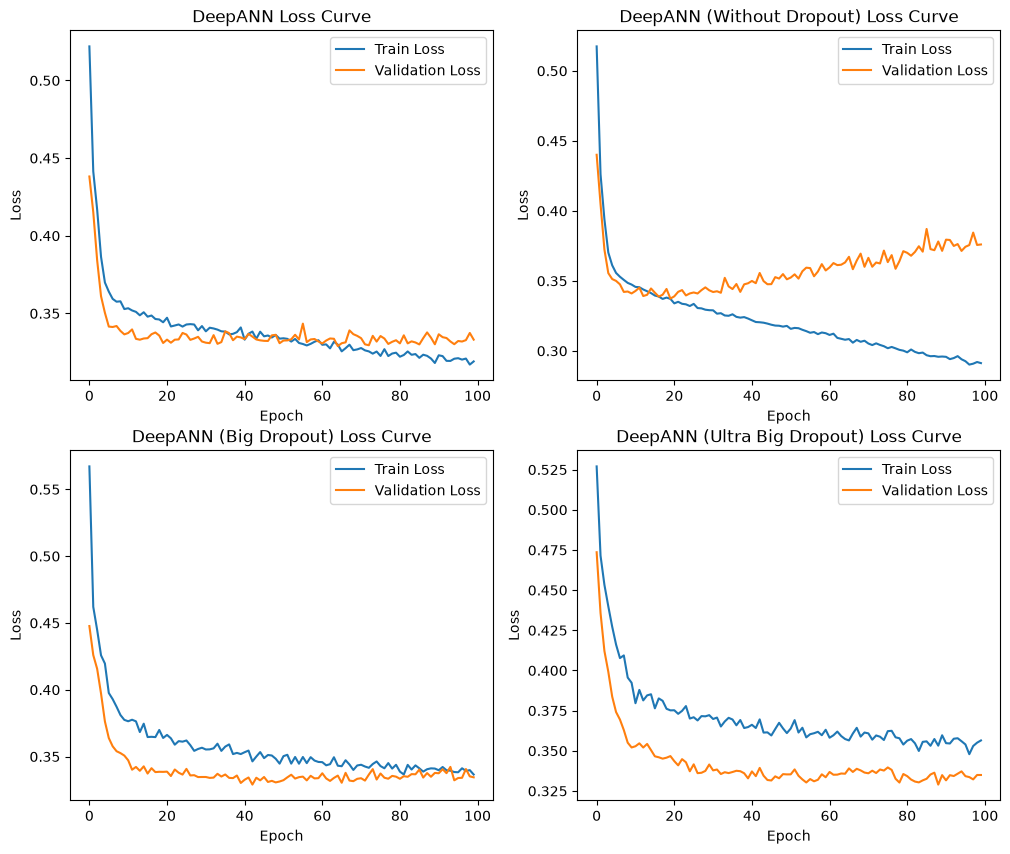

In [29]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 10))

ax1.plot(history_deep["train_loss"], label="Train Loss")
ax1.plot(history_deep["val_loss"], label="Validation Loss")
ax1.set_title("DeepANN Loss Curve")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()

ax2.plot(history_deep_withoutdo["train_loss"], label="Train Loss")
ax2.plot(history_deep_withoutdo["val_loss"], label="Validation Loss")
ax2.set_title("DeepANN (Without Dropout) Loss Curve")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Loss")
ax2.legend()

ax3.plot(history_deep_bigdo["train_loss"], label="Train Loss")
ax3.plot(history_deep_bigdo["val_loss"], label="Validation Loss")
ax3.set_title("DeepANN (Big Dropout) Loss Curve")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Loss")
ax3.legend()

ax4.plot(history_deep_ultrabigdo["train_loss"], label="Train Loss")
ax4.plot(history_deep_ultrabigdo["val_loss"], label="Validation Loss")
ax4.set_title("DeepANN (Ultra Big Dropout) Loss Curve")
ax4.set_xlabel("Epoch")
ax4.set_ylabel("Loss")
ax4.legend()

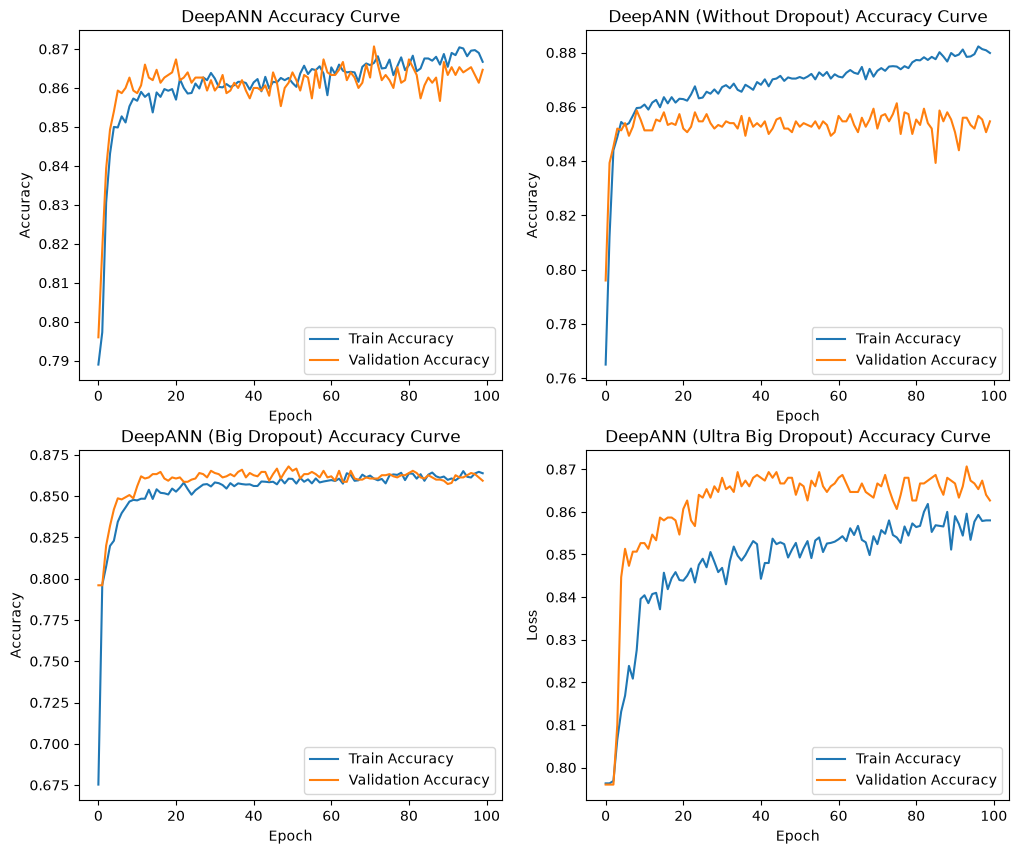

In [30]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 10))

ax1.plot(history_deep["train_acc"], label="Train Accuracy")
ax1.plot(history_deep["val_acc"], label="Validation Accuracy")
ax1.set_title("DeepANN Accuracy Curve")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Accuracy")
ax1.legend()

ax2.plot(history_deep_withoutdo["train_acc"], label="Train Accuracy")
ax2.plot(history_deep_withoutdo["val_acc"], label="Validation Accuracy")
ax2.set_title("DeepANN (Without Dropout) Accuracy Curve")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy")
ax2.legend()

ax3.plot(history_deep_bigdo["train_acc"], label="Train Accuracy")
ax3.plot(history_deep_bigdo["val_acc"], label="Validation Accuracy")
ax3.set_title("DeepANN (Big Dropout) Accuracy Curve")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Accuracy")
ax3.legend()

ax4.plot(history_deep_ultrabigdo["train_acc"], label="Train Accuracy")
ax4.plot(history_deep_ultrabigdo["val_acc"], label="Validation Accuracy")
ax4.set_title("DeepANN (Ultra Big Dropout) Accuracy Curve")
ax4.set_xlabel("Epoch")
ax4.set_ylabel("Loss")
ax4.legend()

Disini saya memutuskan model yang terbaik adalah `deepANN_bigdo`. karena val_loss dan val_acc nya paling stabil dibandingkan model lainnya. walaupun model `deepANN_ultrabigdo` memiliki val_loss yang lebih rendah, namun val_acc nya tidak stabil (fluktuasi tinggi)

In [31]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.

y_pred_probs_deep = []
y_pred_labels_deep = []

treshold = 0.5

with torch.no_grad():
    for X_test_batch, _ in test_loader:
        logits = model_deep_bigdo(X_test_batch)
        probs = torch.sigmoid(logits)
        labels = (probs > treshold).float()

        y_pred_probs_deep.extend(probs.numpy().flatten())
        y_pred_labels_deep.extend(labels.numpy().flatten())

print(f"Test Accuracy: {accuracy_score(y_test, y_pred_labels_deep):.4f}")
print(f"Test Precision: {precision_score(y_test, y_pred_labels_deep):.4f}")
print(f"Test Recall: {recall_score(y_test, y_pred_labels_deep):.4f}")
print(f"Test F1-Score: {f1_score(y_test, y_pred_labels_deep):.4f}")




Test Accuracy: 0.8700
Test Precision: 0.7989
Test Recall: 0.4820
Test F1-Score: 0.6012


## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

Epoch [10/100], Train Loss: 0.8065, Train Acc: 0.7693, Val Loss: 0.7435, Val Acc: 0.7847
Epoch [20/100], Train Loss: 0.7825, Train Acc: 0.7864, Val Loss: 0.7458, Val Acc: 0.7707
Epoch [30/100], Train Loss: 0.7617, Train Acc: 0.7770, Val Loss: 0.7259, Val Acc: 0.7573
Epoch [40/100], Train Loss: 0.7557, Train Acc: 0.7827, Val Loss: 0.7259, Val Acc: 0.7627
Epoch [50/100], Train Loss: 0.7517, Train Acc: 0.7740, Val Loss: 0.7264, Val Acc: 0.7800
Epoch [60/100], Train Loss: 0.7514, Train Acc: 0.7714, Val Loss: 0.7156, Val Acc: 0.7727
Epoch [70/100], Train Loss: 0.7415, Train Acc: 0.7779, Val Loss: 0.7186, Val Acc: 0.7800
Epoch [80/100], Train Loss: 0.7374, Train Acc: 0.7829, Val Loss: 0.7219, Val Acc: 0.7833
Epoch [90/100], Train Loss: 0.7339, Train Acc: 0.7790, Val Loss: 0.7321, Val Acc: 0.7560
Epoch [100/100], Train Loss: 0.7251, Train Acc: 0.7867, Val Loss: 0.7263, Val Acc: 0.7813
Test Accuracy: 0.7793
Test Precision: 0.4738
Test Recall: 0.7705
Test F1-Score: 0.5868


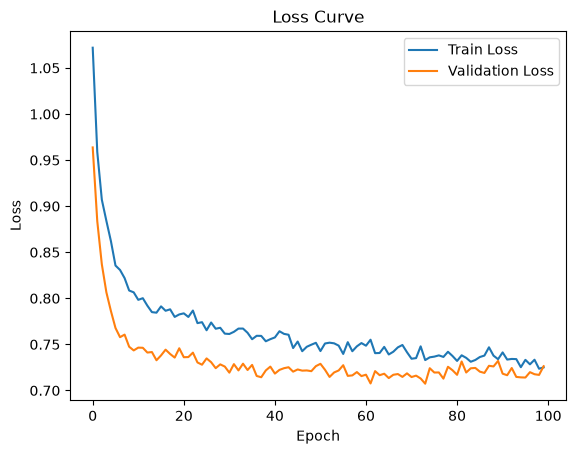

In [32]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung pos_weight = jumlah kelas 0 / jumlah kelas 1 pada train set.
# Masukkan ke loss function: nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight])).

model_deep_imbalanced = DeepANN_bigdo(X_train_tensor.shape[1])

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
loss_fn_imbalanced = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight]))
optimizer_imbalanced = torch.optim.Adam(model_deep_imbalanced.parameters(), lr=0.001)

epoch = 100

history_deep_imbalanced = train_model(
    model=model_deep_imbalanced,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn=loss_fn_imbalanced,
    optimizer=optimizer_imbalanced,
    num_epochs=epoch,
    log_interval=10
)

# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.

y_pred_probs_deep_imbalanced = []
y_pred_labels_deep_imbalanced = []

treshold = 0.5

with torch.no_grad():
    for X_test_batch, _ in test_loader:
        logits = model_deep_imbalanced(X_test_batch)
        probs = torch.sigmoid(logits)
        labels = (probs > treshold).float()

        y_pred_probs_deep_imbalanced.extend(probs.numpy().flatten())
        y_pred_labels_deep_imbalanced.extend(labels.numpy().flatten())

print(f"Test Accuracy: {accuracy_score(y_test, y_pred_labels_deep_imbalanced):.4f}")
print(f"Test Precision: {precision_score(y_test, y_pred_labels_deep_imbalanced):.4f}")
print(f"Test Recall: {recall_score(y_test, y_pred_labels_deep_imbalanced):.4f}")
print(f"Test F1-Score: {f1_score(y_test, y_pred_labels_deep_imbalanced):.4f}")


# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot menggunakan dictionary history.

plt.Figure(figsize=(4, 10))
plt.plot(history_deep_imbalanced["train_loss"], label="Train Loss")
plt.plot(history_deep_imbalanced["val_loss"], label="Validation Loss")
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()



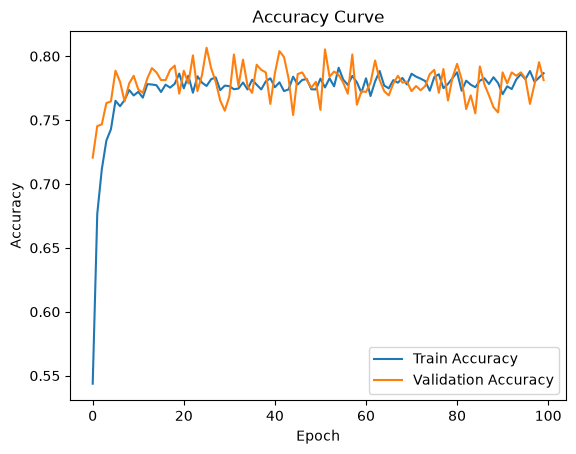

In [33]:
plt.Figure(figsize=(4, 10))
plt.plot(history_deep_imbalanced["train_acc"], label="Train Accuracy")
plt.plot(history_deep_imbalanced["val_acc"], label="Validation Accuracy")
plt.title("Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()


# 4. Evaluasi Model

In [34]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

eval_list = []

for model_name, y_pred_labels in [
    ("Logistic Regression", y_pred),
    ("Simple ANN", y_pred_labels),
    ("Deep ANN", y_pred_labels_deep),
    ("Deep ANN with Class Weight", y_pred_labels_deep_imbalanced)
]:
    accuracy = accuracy_score(y_test, y_pred_labels)
    precision = precision_score(y_test, y_pred_labels)
    recall = recall_score(y_test, y_pred_labels)
    f1 = f1_score(y_test, y_pred_labels)

    eval_list.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })


eval_df = pl.DataFrame(eval_list)
eval_df = eval_df.with_columns([
    pl.col("Accuracy").round(4),
    pl.col("Precision").round(4),
    pl.col("Recall").round(4),
    pl.col("F1-Score").round(4)
])
eval_df

Model,Accuracy,Precision,Recall,F1-Score
str,f64,f64,f64,f64
"""Logistic Regression""",0.8113,0.6196,0.1869,0.2872
"""Simple ANN""",0.8593,0.735,0.482,0.5822
"""Deep ANN""",0.87,0.7989,0.482,0.6012
"""Deep ANN with Class Weight""",0.7793,0.4738,0.7705,0.5868


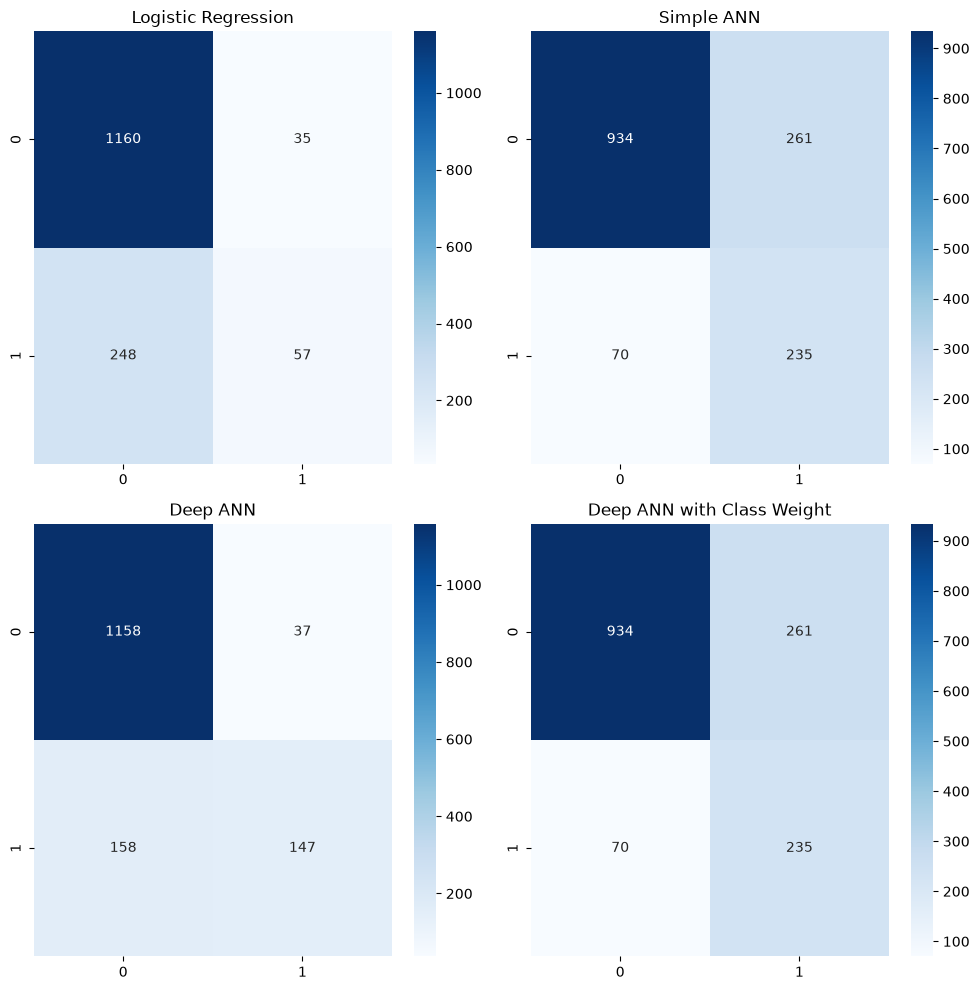

In [35]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(10, 10))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', ax=ax1)
ax1.set_title("Logistic Regression")
sns.heatmap(confusion_matrix(y_test, y_pred_labels), annot=True, fmt='d', cmap='Blues', ax=ax2)
ax2.set_title("Simple ANN")
sns.heatmap(confusion_matrix(y_test, y_pred_labels_deep), annot=True, fmt='d', cmap='Blues', ax=ax3)
ax3.set_title("Deep ANN")
sns.heatmap(confusion_matrix(y_test, y_pred_labels_deep_imbalanced), annot=True, fmt='d', cmap='Blues', ax=ax4)
ax4.set_title("Deep ANN with Class Weight")
plt.tight_layout()

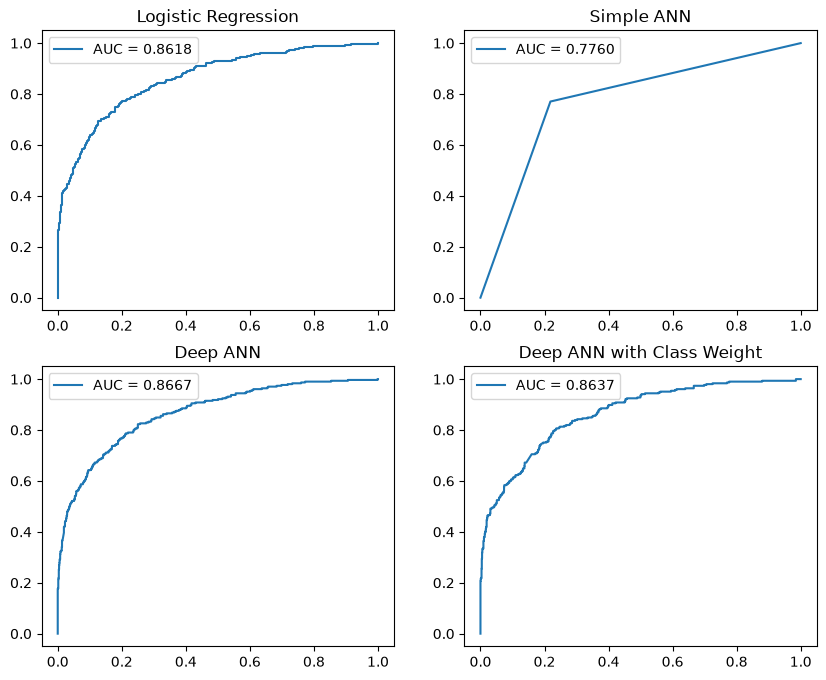

In [36]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.

from sklearn.metrics import roc_curve


fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(10, 8))

ax1.plot(*roc_curve(y_test, y_pred_probs)[:2], label=f"AUC = {roc_auc_score(y_test, y_pred_probs):.4f}")
ax1.set_title("Logistic Regression")
ax1.legend()

ax2.plot(*roc_curve(y_test, y_pred_labels)[:2], label=f"AUC = {roc_auc_score(y_test, y_pred_labels):.4f}")
ax2.set_title("Simple ANN")
ax2.legend()

ax3.plot(*roc_curve(y_test, y_pred_probs_deep)[:2], label=f"AUC = {roc_auc_score(y_test, y_pred_probs_deep):.4f}")
ax3.set_title("Deep ANN")
ax3.legend()

ax4.plot(*roc_curve(y_test, y_pred_probs_deep_imbalanced)[:2], label=f"AUC = {roc_auc_score(y_test, y_pred_probs_deep_imbalanced):.4f}")
ax4.set_title("Deep ANN with Class Weight")
ax4.legend()


In [37]:
torch.save(model_deep.state_dict(), "model_deep.pth")

# 5. Analisis

Dataset Churn Modelling berisi 10.000 nasabah tanpa missing value dan duplikat. Distribusi target Exited tidak seimbang: sekitar 20% nasabah churn (kelas minoritas) dan 80% tidak churn, terlihat dari bar plot distribusi kelas target. EDA tambahan (histogram/KDE fitur numerik dan bar plot churn rate per kategori) menunjukkan cenderung churn lebih tinggi pada pelanggan dari Germany, gender Male, IsActiveMember 0, dan pada segmen tertentu NumOfProducts.

Hasil evaluasi pada test set (berdasarkan tabel evaluasi yang dihasilkan code):

| Model | Accuracy | Precision | Recall | F1-Score |
|---|---|---|---|---|
| Logistic Regression | 0.8113 | 0.6196 | 0.1869 | 0.2872 |
| Simple ANN | 0.8593 | 0.7350 | 0.4820 | 0.5822 |
| Deep ANN (deepANN_bigdo) | 0.8700 | 0.7989 | 0.4820 | 0.6012 |
| Deep ANN with Class Weight | 0.7793 | 0.4738 | 0.7705 | 0.5868 |

Catatan analisis:
1. Logistic Regression sebagai baseline terlemah, terutama recall kelas churn sangat rendah (0.1869), sehingga model hampir tidak mampu menangkap nasabah yang akan churn.
2. Simple ANN (1 hidden layer, 16 neuron) lebih baik dari baseline di semua metrik. Learning curve-nya stabil hingga epoch 100 (train/val loss 0.33, acc 0.86) tanpa tanda overfitting yang jelas.
3. Penambahan layer (DeepANN, 3 hidden layer) tanpa dropout (DeepANN_withoutdo) menunjukkan overfitting: train loss turun ke 0.2913 sementara val loss naik ke 0.3760 pada epoch 100, dan val acc stagnan di sekitar 0.855. Dengan dropout 0.2 pada setiap hidden layer (deepANN_bigdo), train dan val loss stabil (0.33-0.34) serta val acc 0.8593 - ini model paling stabil dan dipilih sebagai terbaik. Dropout lebih besar (deepANN_ultrabigdo, p=0.4) justru membuat val acc fluktuasi dan train acc lebih rendah, tanpa meningkatkan performa.
4. Pemberian class weight (pos_weight = jumlah kelas 0 / kelas 1) meningkatkan recall kelas churn secara dramatis (0.4820 → 0.7705) karena model lebih sensitif terhadap kelas minoritas, dengan trade-off accuracy menurun (0.8700 → 0.7793) dan precision menurun (0.7989 → 0.4738) karena lebih banyak false positive.

# 6. Kesimpulan dan Saran

## Kesimpulan
- ANN outperforms Logistic Regression dalam prediksi customer churn (accuracy test 0.8700 vs 0.8113; F1-score 0.6012 vs 0.2872).
- Model terbaik adalah Deep ANN dengan 3 hidden layer dan Dropout 0.2 pada setiap hidden layer (deepANN_bigdo), karena learning curve val_loss dan val_acc paling stabil tanpa overfitting, dengan accuracy test 0.8700 dan F1-score 0.6012.
- Penambahan layer tanpa dropout menyebabkan overfitting (val loss naik seiring penurunan train loss). Dropout 0.2 menstabilkan model, sementara dropout 0.4 terlalu agresif (val acc fluktuasi).
- Class weight berhasil menangkap lebih banyak nasabah churn (recall 0.7705), tetapi dengan biaya banyak false positive dan accuracy lebih rendah. Pendekatan ini cocok jika biaya melewatkan nasabah churn lebih tinggi dari biaya false alarm.

## Saran
- Coba threshold prediksi selain 0.5 untuk menyesuaikan trade-off precision-recall sesuai kebutuhan bisnis.
- Tambahkan fitur engineered (misalnya rasio saldo terhadap gaji, kategori tenure).
- Lakukan hyperparameter tuning (learning rate, ukuran hidden layer, dropout rate) dengan early stopping berdasarkan val loss.
- Evaluasi tambahan dengan metrik cost-sensitive karena data imbalanced dan biaya kesalahan klasifikasi tidak simetris.